# Обыкновенные дифференциальные уравнения. Практика 2
Задачи для самостоятельного решения из `Дифференциальные уравнения. Практика 2.pdf`.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp

def _grid(f,x0,y0,h,n):
    y = np.zeros((n+1,*np.shape(y0)))
    y[0] = y0
    return x0+h*np.arange(n+1),y

def euler(f,x0,y0,h,n):
    x,y = _grid(f,x0,y0,h,n)
    for i in range(n):
        y[i+1] = y[i]+h*np.asarray(f(x[i],y[i]))
    return x,y

def heun(f,x0,y0,h,n):
    x,y = _grid(f,x0,y0,h,n)
    for i in range(n):
        k1 = np.asarray(f(x[i],y[i])); k2 = np.asarray(f(x[i]+h,y[i]+h*k1))
        y[i+1] = y[i]+h/2*(k1+k2)
    return x,y

def rk4(f,x0,y0,h,n):
    x,y = _grid(f,x0,y0,h,n)
    for i in range(n):
        k1 = np.asarray(f(x[i],y[i])); k2 = np.asarray(f(x[i]+h/2,y[i]+h/2*k1))
        k3 = np.asarray(f(x[i]+h/2,y[i]+h/2*k2)); k4 = np.asarray(f(x[i]+h,y[i]+h*k3))
        y[i+1] = y[i]+h/6*(k1+2*k2+2*k3+k4)
    return x,y

## Блок А. Аналитика и начальные условия
**А1.** $y'=xy$, $y(0)=2$. $\ \dfrac{dy}{y}=x\,dx$, $y=Ce^{x^2/2}$, $C=2$: $\boxed{y=2e^{x^2/2}}$.

**А2.** $y'+y=e^x$, $y(0)=0$. Общее решение $y=\dfrac12e^x+Ce^{-x}$, $C=-\dfrac12$: $\boxed{y=\operatorname{sh}x}$.

**А3.** $y'=-ky$, $y(0)=y_0$: $\boxed{y=y_0e^{-kx}}$.

**А4.** $y'=y\cos x$, $y(0)=1$: $\boxed{y=e^{\sin x}}$.

**А5.** $y'=\dfrac xy$, $y(0)=2$. $\ y^2=x^2+C$, $C=4$; знак корня определяется условием $y(0)>0$: $\boxed{y=\sqrt{x^2+4}}$.

**А6.** $y'=ry(1-y/K)$, $y(0)=y_0$. Разделяем: $\dfrac{K\,dy}{y(K-y)}=r\,dx$, то есть $\ln\left|\dfrac{y}{K-y}\right|=rx+C$. С учётом условия получаем логистическую кривую:
$$\boxed{y=\frac{K}{1+\left(\dfrac{K}{y_0}-1\right)e^{-rx}}}.$$

In [2]:
x = sp.symbols('x',real=True); k,r,K,y0 = sp.symbols('k r K y0',positive=True)
tasks = [('А1',2*sp.exp(x**2/2),lambda y:x*y,2),
         ('А2',sp.sinh(x),lambda y:sp.exp(x)-y,0),
         ('А3',y0*sp.exp(-k*x),lambda y:-k*y,y0),
         ('А4',sp.exp(sp.sin(x)),lambda y:y*sp.cos(x),1),
         ('А5',sp.sqrt(x**2+4),lambda y:x/y,2),
         ('А6',K/(1+(K/y0-1)*sp.exp(-r*x)),lambda y:r*y*(1-y/K),y0)]
for name,sol,f,ic in tasks:
    assert sp.simplify(sp.diff(sol,x)-f(sol))==0 and sp.simplify(sol.subs(x,0)-ic)==0
    print(name,'проверено: уравнение и начальное условие выполнены')

А1 проверено: уравнение и начальное условие выполнены
А2 проверено: уравнение и начальное условие выполнены
А3 проверено: уравнение и начальное условие выполнены
А4 проверено: уравнение и начальное условие выполнены
А5 проверено: уравнение и начальное условие выполнены
А6 проверено: уравнение и начальное условие выполнены


## Блок Б. Реализация методов
**Б1.** Методы Эйлера, Хойна и RK4 реализованы в первой ячейке. Проверим их на значениях из разбора в практике: для $y'=-2y$, $y(0)=1$, $h=0{,}1$.

In [3]:
f = lambda x,y:-2*y
exact = lambda x:np.exp(-2*x)
_,ye = euler(f,0,1.,.1,3); _,yh = heun(f,0,1.,.1,2); _,yr = rk4(f,0,1.,.1,1)
print('Эйлер:',ye); print('Хойн:',yh); print('RK4 y1 =',yr[1],' точное',exact(.1))
assert np.allclose(ye,[1,.8,.64,.512]) and np.allclose(yh,[1,.82,.6724]) and np.isclose(yr[1],.81873333333)

Эйлер: [1.    0.8   0.64  0.512]
Хойн: [1.     0.82   0.6724]
RK4 y1 = 0.8187333333333333  точное 0.8187307530779818


**Б2–Б3.** Точное и численные решения при $h=0{,}1$; ошибка как функция от $x$.

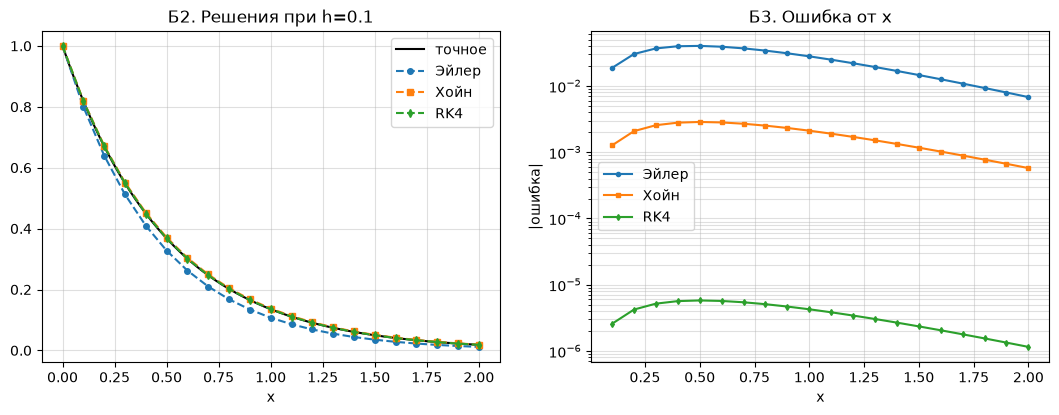

In [4]:
methods = {'Эйлер':euler,'Хойн':heun,'RK4':rk4}
xx = np.linspace(0,2,300)
fig,axs = plt.subplots(1,2,figsize=(13,4.3))
axs[0].plot(xx,exact(xx),'k',label='точное')
for (nm,m),mk in zip(methods.items(),'osd'):
    X,Y = m(f,0,1.,.1,20)
    axs[0].plot(X,Y,mk+'--',ms=4,label=nm); axs[1].semilogy(X[1:],np.abs(Y-exact(X))[1:],mk+'-',ms=3,label=nm)
axs[0].set_title('Б2. Решения при h=0.1'); axs[1].set_title('Б3. Ошибка от x'); axs[0].set_xlabel('x'); axs[1].set_xlabel('x'); axs[1].set_ylabel('|ошибка|')
for a in axs: a.grid(True,which='both',alpha=.4); a.legend()
fig.savefig('fig/DE2_B23.png',dpi=120,bbox_inches='tight'); plt.show()

**Б4–Б5.** Ошибка при $x=2$ как функция от $h$ в лог-лог масштабе. Наклон прямой равен порядку метода. Б5 — то же на другой задаче: $y'=xy$, $y(0)=1$, $y=e^{x^2/2}$.

Б4. $y'=-2y$ Эйлер порядок 0.943
Б4. $y'=-2y$ Хойн порядок 2.119
Б4. $y'=-2y$ RK4 порядок 4.109
Б5. $y'=xy$ Эйлер порядок 0.882
Б5. $y'=xy$ Хойн порядок 1.943
Б5. $y'=xy$ RK4 порядок 3.924


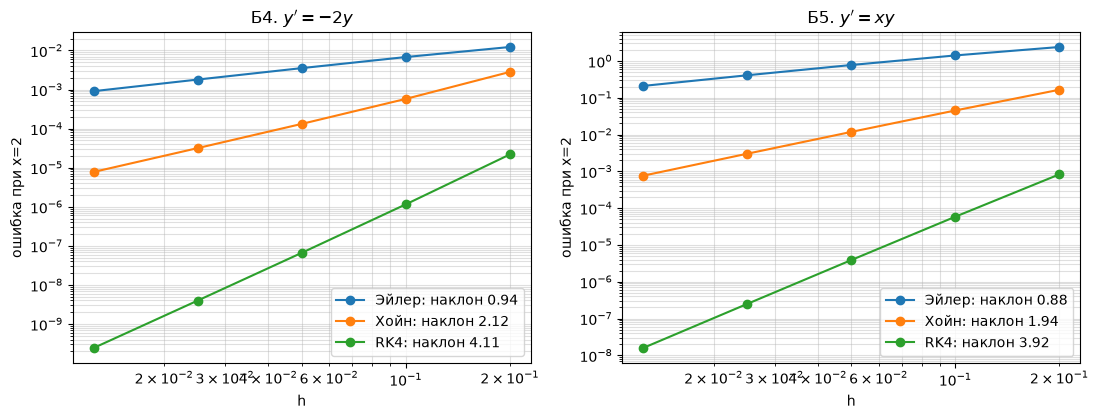

In [5]:
def orders(f,exact,T,hs):
    res = {}
    for nm,m in methods.items():
        errs = []
        for h in hs:
            N = int(round(T/h)); X,Y = m(f,0,1.,T/N,N); errs.append(abs(Y[-1]-exact(T)))
        res[nm] = (np.array(errs),np.polyfit(np.log(hs),np.log(errs),1)[0])
    return res

hs = np.array([.2,.1,.05,.025,.0125])
r1 = orders(f,exact,2.,hs); r2 = orders(lambda x,y:x*y,lambda x:np.exp(x*x/2),2.,hs)
fig,axs = plt.subplots(1,2,figsize=(13,4.3))
for ax,res,tl in ((axs[0],r1,"Б4. $y'=-2y$"),(axs[1],r2,"Б5. $y'=xy$")):
    for nm,(errs,sl) in res.items():
        ax.loglog(hs,errs,'o-',label=f'{nm}: наклон {sl:.2f}'); print(tl,nm,f'порядок {sl:.3f}')
    ax.set_xlabel('h'); ax.set_ylabel('ошибка при x=2'); ax.grid(True,which='both',alpha=.4); ax.legend(); ax.set_title(tl)
fig.savefig('fig/DE2_B45.png',dpi=120,bbox_inches='tight'); plt.show()
for res in (r1,r2):
    for (nm,(_,sl)),p in zip(res.items(),(1,2,4)):
        assert abs(sl-p)<.25,(nm,sl)

**Вывод.** На обеих задачах наклоны близки к $1$, $2$ и $4$, то есть порядки методов совпадают и не зависят от уравнения.

## Блок В. Системы
**В1–В2.** Маятник $\theta'=\omega$, $\omega'=-\dfrac gL\sin\theta$ при $g=9{,}81$, $L=1$, $\theta(0)=\pi/4$, $\omega(0)=0$, решённый своим RK4. Сравниваем с библиотечным решателем и проверяем сохранение энергии.

макс. отличие от эталона: 1.4479952474555358e-07
дрейф энергии: 3.334111831065911e-08


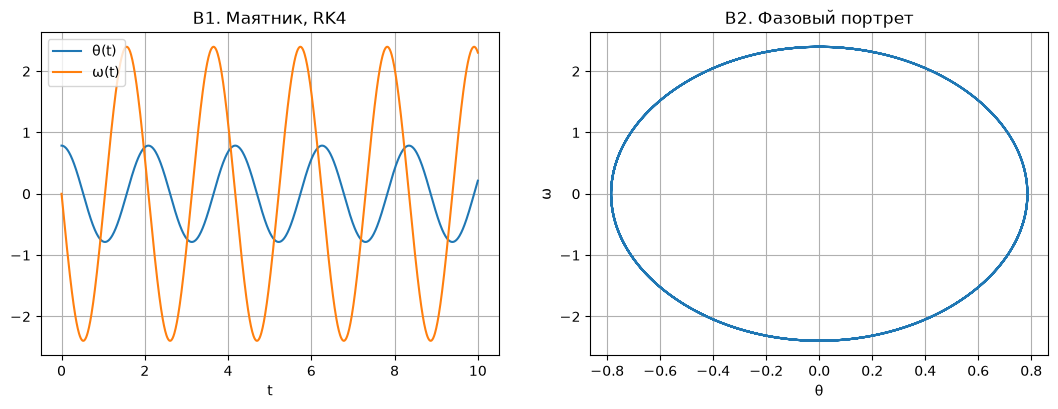

In [6]:
g,L = 9.81,1.
pend = lambda t,s:np.array([s[1],-(g/L)*np.sin(s[0])])
T,S = rk4(pend,0,np.array([np.pi/4,0.]),.01,1000)
ref = solve_ivp(pend,[0,10],[np.pi/4,0],t_eval=T,rtol=1e-11,atol=1e-12,method='DOP853')
print('макс. отличие от эталона:',np.abs(S[:,0]-ref.y[0]).max())
E = S[:,1]**2/2-(g/L)*np.cos(S[:,0]); print('дрейф энергии:',np.ptp(E))
assert np.abs(S[:,0]-ref.y[0]).max()<1e-6
fig,axs = plt.subplots(1,2,figsize=(13,4.2))
axs[0].plot(T,S[:,0],label='θ(t)'); axs[0].plot(T,S[:,1],label='ω(t)'); axs[0].legend(); axs[0].grid(True); axs[0].set_xlabel('t'); axs[0].set_title('В1. Маятник, RK4')
axs[1].plot(S[:,0],S[:,1]); axs[1].set_xlabel('θ'); axs[1].set_ylabel('ω'); axs[1].grid(True); axs[1].set_title('В2. Фазовый портрет')
fig.savefig('fig/DE2_V12.png',dpi=120,bbox_inches='tight'); plt.show()

**В3–В4.** SIR-модель: $S'=-\beta SI$, $I'=\beta SI-\gamma I$, $R'=\gamma I$, $\beta=0{,}3$, $\gamma=0{,}1$, $S(0)=0{,}99$, $I(0)=0{,}01$, $R(0)=0$.

**Контроль пика.** Разделив $I'$ на $S'$, получаем $\dfrac{dI}{dS}=-1+\dfrac{\gamma}{\beta S}$. Пик наступает при $S=\gamma/\beta$, откуда
$$I_{\max}=S_0+I_0-\frac\gamma\beta\left(1+\ln\frac{\beta S_0}{\gamma}\right).$$

В4. Пик I = 0.30381 при t = 26.63; формула даёт 0.30381


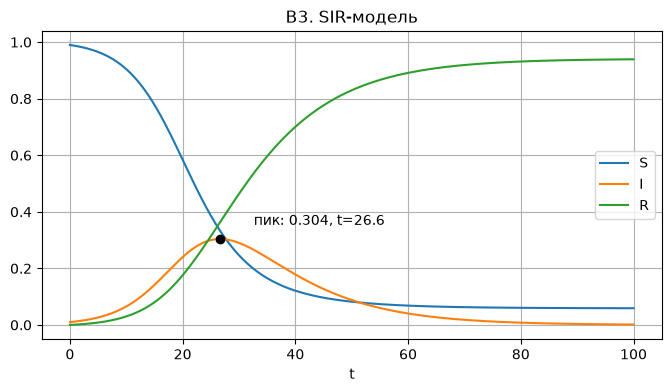

In [7]:
beta,gamma = .3,.1
sir = lambda t,s:np.array([-beta*s[0]*s[1],beta*s[0]*s[1]-gamma*s[1],gamma*s[1]])
T,Y = rk4(sir,0,np.array([.99,.01,0.]),.01,10000)
i = Y[:,1].argmax(); theory = .99+.01-(gamma/beta)*(1+np.log(beta*.99/gamma))
print(f'В4. Пик I = {Y[i,1]:.5f} при t = {T[i]:.2f}; формула даёт {theory:.5f}')
assert abs(Y[i,1]-theory)<1e-6 and np.allclose(Y.sum(axis=1),1)
fig,ax = plt.subplots(figsize=(8,4))
for j,l in enumerate('SIR'): ax.plot(T,Y[:,j],label=l)
ax.plot(T[i],Y[i,1],'ko'); ax.annotate(f'пик: {Y[i,1]:.3f}, t={T[i]:.1f}',(T[i],Y[i,1]),xytext=(T[i]+6,Y[i,1]+.05)); ax.legend(); ax.grid(True); ax.set_xlabel('t'); ax.set_title('В3. SIR-модель')
fig.savefig('fig/DE2_V34.png',dpi=120,bbox_inches='tight'); plt.show()

**В5.** Хищник—жертва: $x'=\alpha x-\beta xy$, $y'=-\gamma y+\delta xy$. В листке значения параметров не заданы, поэтому берём типичные: $\alpha=1{,}1$, $\beta=0{,}4$, $\gamma=0{,}4$, $\delta=0{,}1$.

Равновесие: $(\gamma/\delta,\ \alpha/\beta)=(4;\ 2{,}75)$. Система имеет первый интеграл $V=\delta x-\gamma\ln x+\beta y-\alpha\ln y$, поэтому траектории замкнуты. Это проверяется численно.

старт (10,2): дрейф V = 1.03e-11
старт (6,2): дрейф V = 7.08e-13


старт (5,3): дрейф V = 3.73e-14
старт (14,3): дрейф V = 5.54e-11


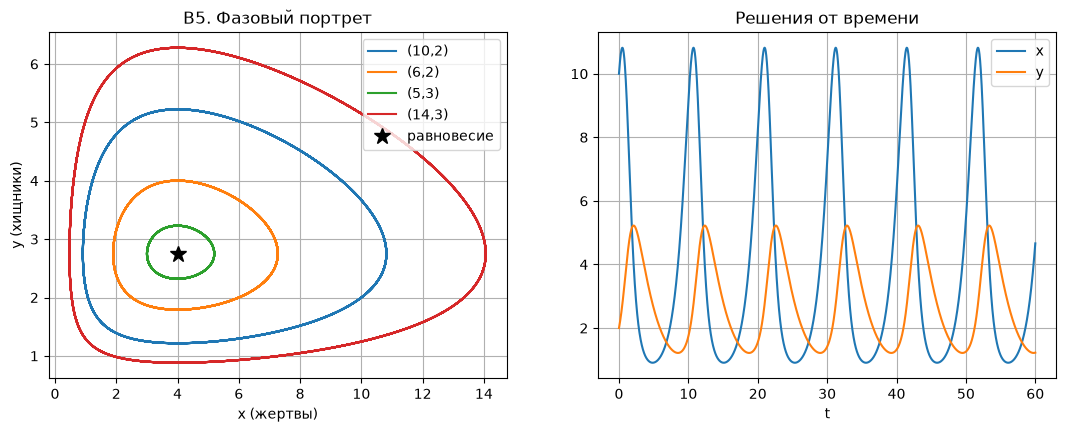

In [8]:
a,b,c,d = 1.1,.4,.4,.1
lv = lambda t,s:np.array([a*s[0]-b*s[0]*s[1],-c*s[1]+d*s[0]*s[1]])
V = lambda s:d*s[:,0]-c*np.log(s[:,0])+b*s[:,1]-a*np.log(s[:,1])
fig,axs = plt.subplots(1,2,figsize=(13,4.5))
for x0,y0 in [(10,2),(6,2),(5,3),(14,3)]:
    T,Y = rk4(lv,0,np.array([x0,y0],float),.005,16000)
    print(f'старт ({x0},{y0}): дрейф V = {np.ptp(V(Y)):.2e}'); assert np.ptp(V(Y))<1e-6
    axs[0].plot(Y[:,0],Y[:,1],label=f'({x0},{y0})')
axs[0].plot(c/d,a/b,'k*',ms=12,label='равновесие'); axs[0].set_xlabel('x (жертвы)'); axs[0].set_ylabel('y (хищники)'); axs[0].grid(True); axs[0].legend(); axs[0].set_title('В5. Фазовый портрет')
T,Y = rk4(lv,0,np.array([10,2.]),.005,12000)
axs[1].plot(T,Y[:,0],label='x'); axs[1].plot(T,Y[:,1],label='y'); axs[1].set_xlabel('t'); axs[1].legend(); axs[1].grid(True); axs[1].set_title('Решения от времени')
fig.savefig('fig/DE2_V5.png',dpi=120,bbox_inches='tight'); plt.show()